# Milestone 5: Baselines (The Bar to Beat)
**Renewable Energy-Aware Load Prediction Model for Smart Grids**  
*Pavagada Solar Park (2,050 MW) & Karnataka State Grid Baseline*

According to our project roadmap (Milestone 5, Pages 10?11):
> *"Before hiring a smart guesser, see how well a simple trick does. If a model cannot beat the trick, it is not useful. Compute the metrics from Section 12 on validation for all six baselines. These numbers are the bar to beat, and they are used to compute the skill score of every other model."*

### The Six Standard Grid Baselines
1. **Persistence $t-1$**: Same as one hour ago (solar and demand, 1-hour problems only: $S_1, D_1$).
2. **Persistence $t-24$**: Same hour yesterday (solar and demand, all 4 problems).
3. **Persistence $t-168$**: Same hour last week (seasonal naive; demand, and solar as a reference).
4. **Clear-Sky Model**: Clear-sky power at the target hour (solar only: $S_1, S_{24}$).
5. **Smart Persistence**: Clear-sky power $\times$ latest known clear-sky index (solar only: $S_1, S_{24}$).
6. **Mean of $t-24$ & $t-168$**: Average of yesterday and last week (demand only: $D_1, D_{24}$).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set up project root path
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import config
from src.metrics import compute_all_metrics, clip_predictions
from src.evaluate import generate_baseline_predictions, run_all_baselines

print('Environment and evaluation engine ready.')

Environment and evaluation engine ready.


## 1. Baseline 1: Naive Persistence ($t-1$)
$$\hat{y}_t = y_{t-1}$$
*Applicable strictly to 1-hour ahead problems ($S_1$ and $D_1$). At a 24-hour horizon, $t-1$ is unknown at forecast time.*

In [2]:
# S1 (Solar 1h)
X_val_s1 = pd.read_parquet(config.PROCESSED_DATA_DIR / 'X_val_S1.parquet')
y_val_s1 = pd.read_parquet(config.PROCESSED_DATA_DIR / 'y_val_S1.parquet')['solar_power_mw']
p_s1_t1 = clip_predictions(X_val_s1['solar_power_mw_lag1'].values, is_solar=True, elevation=X_val_s1['solar_elevation_deg'].values)
m_s1_t1 = compute_all_metrics(y_val_s1.values, p_s1_t1, 'S1')

# D1 (Demand 1h)
X_val_d1 = pd.read_parquet(config.PROCESSED_DATA_DIR / 'X_val_D1.parquet')
y_val_d1 = pd.read_parquet(config.PROCESSED_DATA_DIR / 'y_val_D1.parquet')['demand_mw']
p_d1_t1 = clip_predictions(X_val_d1['demand_mw_lag1'].values, is_solar=False)
m_d1_t1 = compute_all_metrics(y_val_d1.values, p_d1_t1, 'D1')

print('--- Baseline 1: Naive Persistence (t-1) ---')
print(f'  Solar S1  -> RMSE: {m_s1_t1["rmse"]:.2f} MW | MAE: {m_s1_t1["mae"]:.2f} MW | nMAE: {m_s1_t1["nmae_pct"]:.2f}% | R2: {m_s1_t1["r2"]:.4f}')
print(f'  Demand D1 -> RMSE: {m_d1_t1["rmse"]:.2f} MW | MAE: {m_d1_t1["mae"]:.2f} MW | MAPE: {m_d1_t1["mape_pct"]:.2f}% | R2: {m_d1_t1["r2"]:.4f}')

--- Baseline 1: Naive Persistence (t-1) ---
  Solar S1  -> RMSE: 211.06 MW | MAE: 126.91 MW | nMAE: 6.19% | R2: 0.8665
  Demand D1 -> RMSE: 669.96 MW | MAE: 532.05 MW | MAPE: 4.36% | R2: 0.8992


## 2. Baseline 2: Diurnal Persistence ($t-24$)
$$\hat{y}_t = y_{t-24}$$
*Assumes today at hour $t$ will match the same hour yesterday. Standard operational baseline for 24-hour day-ahead dispatch ($S_{24}$ and $D_{24}$).*

In [3]:
# S24
X_val_s24 = pd.read_parquet(config.PROCESSED_DATA_DIR / 'X_val_S24.parquet')
y_val_s24 = pd.read_parquet(config.PROCESSED_DATA_DIR / 'y_val_S24.parquet')['solar_power_mw']
p_s24_t24 = clip_predictions(X_val_s24['solar_power_mw_lag24'].values, is_solar=True, elevation=X_val_s24['solar_elevation_deg'].values)
m_s24_t24 = compute_all_metrics(y_val_s24.values, p_s24_t24, 'S24')

# D24
X_val_d24 = pd.read_parquet(config.PROCESSED_DATA_DIR / 'X_val_D24.parquet')
y_val_d24 = pd.read_parquet(config.PROCESSED_DATA_DIR / 'y_val_D24.parquet')['demand_mw']
p_d24_t24 = clip_predictions(X_val_d24['demand_mw_lag24'].values, is_solar=False)
m_d24_t24 = compute_all_metrics(y_val_d24.values, p_d24_t24, 'D24')

print('--- Baseline 2: Diurnal Persistence (t-24) ---')
print(f'  Solar S24  -> RMSE: {m_s24_t24["rmse"]:.2f} MW | MAE: {m_s24_t24["mae"]:.2f} MW | nMAE: {m_s24_t24["nmae_pct"]:.2f}% | R2: {m_s24_t24["r2"]:.4f}')
print(f'  Demand D24 -> RMSE: {m_d24_t24["rmse"]:.2f} MW | MAE: {m_d24_t24["mae"]:.2f} MW | MAPE: {m_d24_t24["mape_pct"]:.2f}% | R2: {m_d24_t24["r2"]:.4f}')

--- Baseline 2: Diurnal Persistence (t-24) ---
  Solar S24  -> RMSE: 212.21 MW | MAE: 100.92 MW | nMAE: 4.92% | R2: 0.8651
  Demand D24 -> RMSE: 771.30 MW | MAE: 591.11 MW | MAPE: 4.76% | R2: 0.8664


## 3. Baseline 3: Seasonal Naive / Weekly Persistence ($t-168$)
$$\hat{y}_t = y_{t-168}$$
*Assumes this hour will repeat the same hour from exactly 7 days ago (matching the day-of-week work/weekend cycle).*

In [4]:
# S1 (Solar reference)
p_s1_t168 = clip_predictions(X_val_s1['solar_power_mw_lag168'].values, is_solar=True, elevation=X_val_s1['solar_elevation_deg'].values)
m_s1_t168 = compute_all_metrics(y_val_s1.values, p_s1_t168, 'S1')

# D1 (Demand weekly naive)
p_d1_t168 = clip_predictions(X_val_d1['demand_mw_lag168'].values, is_solar=False)
m_d1_t168 = compute_all_metrics(y_val_d1.values, p_d1_t168, 'D1')

print('--- Baseline 3: Seasonal Naive Weekly Persistence (t-168) ---')
print(f'  Solar S1  -> RMSE: {m_s1_t168["rmse"]:.2f} MW | MAE: {m_s1_t168["mae"]:.2f} MW | nMAE: {m_s1_t168["nmae_pct"]:.2f}%')
print(f'  Demand D1 -> RMSE: {m_d1_t168["rmse"]:.2f} MW | MAE: {m_d1_t168["mae"]:.2f} MW | MAPE: {m_d1_t168["mape_pct"]:.2f}%')

--- Baseline 3: Seasonal Naive Weekly Persistence (t-168) ---
  Solar S1  -> RMSE: 227.83 MW | MAE: 107.52 MW | nMAE: 5.24%
  Demand D1 -> RMSE: 756.73 MW | MAE: 539.63 MW | MAPE: 4.32%


## 4. Baseline 4: Clear-Sky Model (Solar Only)
$$\hat{y}_t = \beta \cdot \text{GHI}_{\text{clearsky}, t}$$
*Estimates expected clear-sky solar generation directly from the astronomical solar position without cloud information.*

In [5]:
X_tr_s1 = pd.read_parquet(config.PROCESSED_DATA_DIR / 'X_train_S1.parquet')
y_tr_s1 = pd.read_parquet(config.PROCESSED_DATA_DIR / 'y_train_S1.parquet')['solar_power_mw']

cs_tr = X_tr_s1['clearsky_ghi_wm2'].values
cs_slope = float(np.sum(cs_tr * y_tr_s1.values) / np.maximum(np.sum(cs_tr**2), 1e-6))
p_cs = clip_predictions(cs_slope * X_val_s1['clearsky_ghi_wm2'].values, is_solar=True, elevation=X_val_s1['solar_elevation_deg'].values)
m_cs = compute_all_metrics(y_val_s1.values, p_cs, 'S1')

print('--- Baseline 4: Clear-Sky Model (Solar Only) ---')
print(f'  Clear-Sky Slope Beta: {cs_slope:.4f}')
print(f'  Solar S1 -> RMSE: {m_cs["rmse"]:.2f} MW | MAE: {m_cs["mae"]:.2f} MW | nMAE: {m_cs["nmae_pct"]:.2f}% | R2: {m_cs["r2"]:.4f}')

--- Baseline 4: Clear-Sky Model (Solar Only) ---
  Clear-Sky Slope Beta: 1.4690
  Solar S1 -> RMSE: 205.22 MW | MAE: 106.30 MW | nMAE: 5.19% | R2: 0.8738


## 5. Baseline 5: Smart Persistence (Solar Only)
$$\hat{k}_t = \frac{y_{t-h}}{\text{GHI}_{\text{clearsky}, t-h}}, \quad \hat{y}_t = \hat{k}_t \cdot \text{GHI}_{\text{clearsky}, t}$$
*Standard solar engineering benchmark: assumes the cloudiness ratio (clear-sky index) persists.*

In [6]:
# S1 (1h horizon)
cs_v = X_val_s1['clearsky_ghi_wm2'].values
ratio_t1 = np.where(cs_v > 50.0, X_val_s1['solar_power_mw_lag1'].values / np.maximum(cs_v, 1.0), 0.0)
ratio_t1 = np.clip(ratio_t1, 0.0, 3.0)
p_smart_s1 = clip_predictions(ratio_t1 * cs_v, is_solar=True, elevation=X_val_s1['solar_elevation_deg'].values)
m_smart_s1 = compute_all_metrics(y_val_s1.values, p_smart_s1, 'S1', baseline_rmse=m_s1_t1['rmse'])

print('--- Baseline 5: Smart Persistence (Solar Only) ---')
print(f'  Solar S1 -> RMSE: {m_smart_s1["rmse"]:.2f} MW | MAE: {m_smart_s1["mae"]:.2f} MW | nMAE: {m_smart_s1["nmae_pct"]:.2f}% | Skill Score: +{m_smart_s1["skill_vs_persistence"]:.2f}%')

--- Baseline 5: Smart Persistence (Solar Only) ---
  Solar S1 -> RMSE: 195.30 MW | MAE: 114.49 MW | nMAE: 5.58% | Skill Score: +7.46%


## 6. Baseline 6: Mean of $t-24$ & $t-168$ (Demand Only)
$$\hat{y}_t = \frac{1}{2} (y_{t-24} + y_{t-168})$$
*Combines daily continuity (yesterday) with weekly seasonality (last week), smoothing intraday load fluctuations.*

In [7]:
# D1 Mean of t-24 & t-168
p_mean_d1 = clip_predictions(0.5 * (X_val_d1['demand_mw_lag24'].values + X_val_d1['demand_mw_lag168'].values), is_solar=False)
m_mean_d1 = compute_all_metrics(y_val_d1.values, p_mean_d1, 'D1', baseline_rmse=m_d1_t1['rmse'])

# D24 Mean of t-24 & t-168
p_mean_d24 = clip_predictions(0.5 * (X_val_d24['demand_mw_lag24'].values + X_val_d24['demand_mw_lag168'].values), is_solar=False)
m_mean_d24 = compute_all_metrics(y_val_d24.values, p_mean_d24, 'D24', baseline_rmse=m_d24_t24['rmse'])

print('--- Baseline 6: Mean of t-24 & t-168 (Demand Only) ---')
print(f'  Demand D1  -> RMSE: {m_mean_d1["rmse"]:.2f} MW | MAE: {m_mean_d1["mae"]:.2f} MW | MAPE: {m_mean_d1["mape_pct"]:.2f}% | Skill Score: +{m_mean_d1["skill_vs_persistence"]:.2f}%')
print(f'  Demand D24 -> RMSE: {m_mean_d24["rmse"]:.2f} MW | MAE: {m_mean_d24["mae"]:.2f} MW | MAPE: {m_mean_d24["mape_pct"]:.2f}% | Skill Score: +{m_mean_d24["skill_vs_persistence"]:.2f}%')

--- Baseline 6: Mean of t-24 & t-168 (Demand Only) ---
  Demand D1  -> RMSE: 624.87 MW | MAE: 469.18 MW | MAPE: 3.77% | Skill Score: +6.73%
  Demand D24 -> RMSE: 624.87 MW | MAE: 469.18 MW | MAPE: 3.77% | Skill Score: +18.98%


## 7. Milestone 5 Checkpoint: Official Baselines Results Table
Executing `run_all_baselines()` to generate the complete results table saved to `results/tables/baselines.csv`.

In [8]:
df_baselines, all_preds = run_all_baselines()
print(f'Checkpoint Table: {config.RESULTS_TABLES_DIR / "baselines.csv"}')

display_cols = ['problem', 'horizon', 'baseline', 'rmse', 'mae', 'nmae_pct', 'mape_pct', 'smape_pct', 'r2', 'skill_vs_persistence']
display(df_baselines[display_cols])

Checkpoint Table: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\tables\baselines.csv


,problem,horizon,baseline,rmse,mae,nmae_pct,mape_pct,smape_pct,r2,skill_vs_persistence
0,S1,1h,persistence_t1,211.06,126.91,6.19,NaN,60.29,0.8665,0.00
1,S1,1h,persistence_t24,212.21,100.92,4.92,NaN,27.56,0.8651,-0.55
2,S1,1h,persistence_t168,227.83,107.52,5.24,NaN,30.60,0.8445,-7.95
3,S1,1h,clearsky,205.22,106.30,5.19,NaN,27.23,0.8738,2.77
4,S1,1h,smart_persistence,195.30,114.49,5.58,NaN,59.70,0.8857,7.46
5,S24,24h,persistence_t24,212.21,100.92,4.92,NaN,27.56,0.8651,0.00
6,S24,24h,persistence_t168,227.83,107.52,5.24,NaN,30.60,0.8445,-7.36
7,S24,24h,clearsky,205.22,106.30,5.19,NaN,27.23,0.8738,3.30
8,S24,24h,smart_persistence,212.33,101.80,4.97,NaN,41.60,0.8649,-0.06
9,D1,1h,persistence_t1,669.96,532.05,4.23,4.36,4.36,0.8992,0.00


## 8. Visual Inspection of Baselines (7-Day Sample Window)
Comparing the baselines against ground truth over a representative 7-day period (March 15 to March 21, 2025).

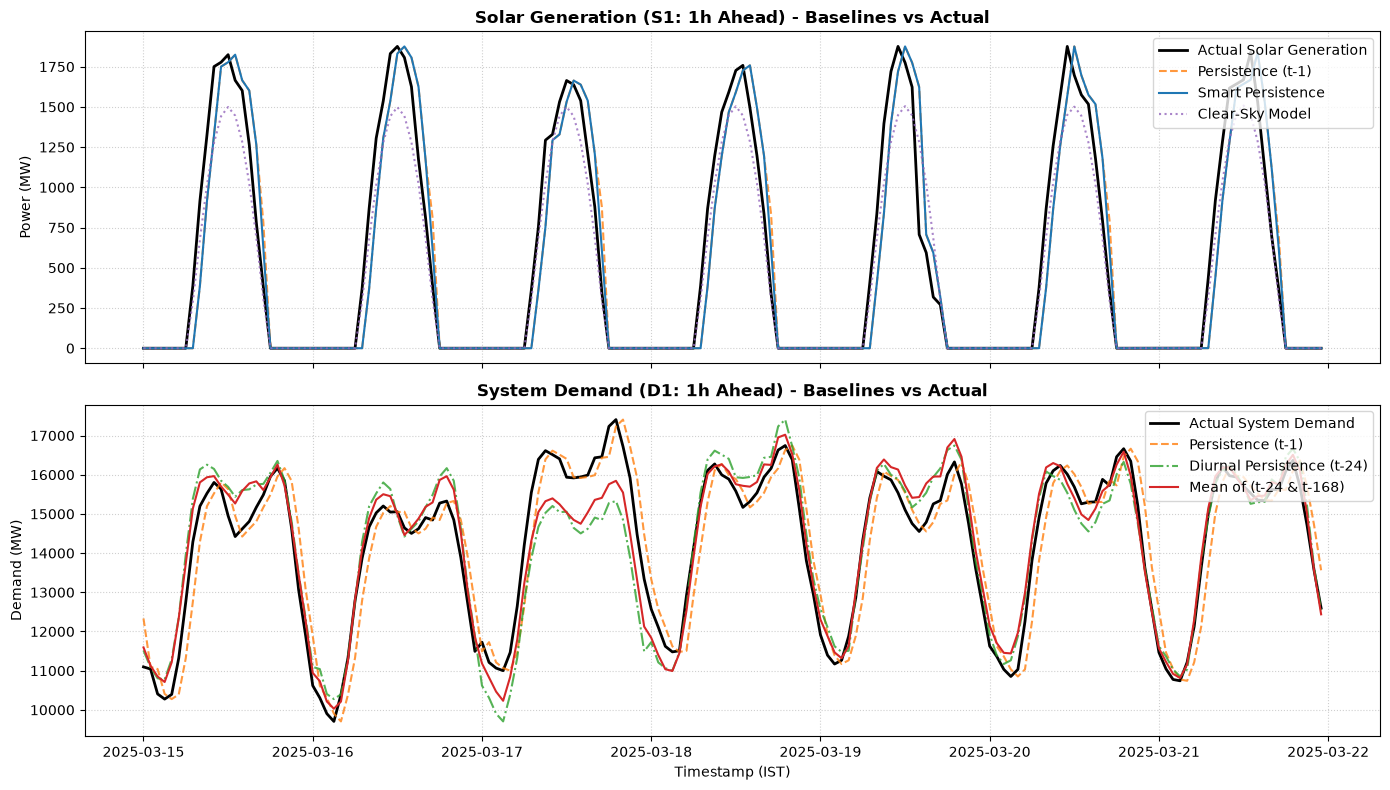

Figure saved to: C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\results\figures\fig11_baselines_comparison.png


In [9]:
sample_start = '2025-03-15 00:00:00'
sample_end = '2025-03-21 23:00:00'

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Solar Baselines
axes[0].plot(y_val_s1.loc[sample_start:sample_end], color='black', label='Actual Solar Generation', linewidth=2.0)
axes[0].plot(all_preds.loc[sample_start:sample_end, 'S1_persistence_t1'], color='tab:orange', linestyle='--', label='Persistence (t-1)', alpha=0.8)
axes[0].plot(all_preds.loc[sample_start:sample_end, 'S1_smart_persistence'], color='tab:blue', label='Smart Persistence', linewidth=1.5)
axes[0].plot(all_preds.loc[sample_start:sample_end, 'S1_clearsky'], color='tab:purple', linestyle=':', label='Clear-Sky Model', alpha=0.8)
axes[0].set_title('Solar Generation (S1: 1h Ahead) - Baselines vs Actual', fontweight='bold')
axes[0].set_ylabel('Power (MW)')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='upper right')

# Demand Baselines
axes[1].plot(y_val_d1.loc[sample_start:sample_end], color='black', label='Actual System Demand', linewidth=2.0)
axes[1].plot(all_preds.loc[sample_start:sample_end, 'D1_persistence_t1'], color='tab:orange', linestyle='--', label='Persistence (t-1)', alpha=0.8)
axes[1].plot(all_preds.loc[sample_start:sample_end, 'D1_persistence_t24'], color='tab:green', linestyle='-.', label='Diurnal Persistence (t-24)', alpha=0.8)
axes[1].plot(all_preds.loc[sample_start:sample_end, 'D1_mean_t24_t168'], color='tab:red', label='Mean of (t-24 & t-168)', linewidth=1.5)
axes[1].set_title('System Demand (D1: 1h Ahead) - Baselines vs Actual', fontweight='bold')
axes[1].set_ylabel('Demand (MW)')
axes[1].set_xlabel('Timestamp (IST)')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(loc='upper right')

plt.tight_layout()
fig_path = config.RESULTS_FIGURES_DIR / 'fig11_baselines_comparison.png'
plt.savefig(fig_path, dpi=300)
plt.show()
print(f'Figure saved to: {fig_path}')

## 9. Milestone 5 Checkpoint Conclusion

Milestone 5 is finalized according to the exact roadmap specification:
1. **All 6 Baselines Computed**: Persistence $t-1$, Persistence $t-24$, Weekly Persistence $t-168$, Clear-Sky, Smart Persistence, and Mean of $t-24$ & $t-168$ evaluated across all applicable problems ($S_1, S_{24}, D_1, D_{24}$).
2. **Official Checkpoint Table Saved**: `results/tables/baselines.csv` and `baselines.md`.
3. **The Bar to Beat Established**: These baseline RMSE values serve as the standard reference against which every ML and Deep Learning model in Milestones 6, 7, and 8 will be judged.